# Protecting-Group Revision for Boceprevir

This tutorial continues [Protection Strategy Scoring](08_Protection_Scoring.ipynb).
We use the same scoring approach to find a problematic Boceprevir route, then add
protection before the affected reactions and remove it later.

## What this tutorial covers

1. **Run planning** for Boceprevir
2. **Extract and score routes** with `tree.routes()`
3. **Revise a problematic route** using a protecting group
4. **Compare the plans** and follow protection across multiple steps

## 1. Setup

Use the GPS rules, ranking policy and a prepared building-block catalogue.
Set `SYNPLAN_DATA` to your resource directory; `SYNPLAN_BUILDING_BLOCKS_JSON`
can point to a different prepared catalogue.

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from chython import depict_settings
from IPython.display import Markdown, display

from synplan.chem.building_blocks import load_building_block_catalogue
from synplan.chem.utils import mol_from_smiles
from synplan.mcts.config import RolloutEvaluationConfig, TreeConfig
from synplan.mcts.tree import Tree
from synplan.utils.loading import (
    load_evaluation_function,
    load_policy_function,
    load_reaction_rules,
)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)
depict_settings(aam=False)  # Draw structures without atom-number labels.

In [2]:
data_dir = Path(os.environ.get("SYNPLAN_DATA", "synplan_data"))
reaction_rules_path = data_dir / "policy/supervised_gps/v1/reaction_rules.tsv"
ranking_policy_path = data_dir / "policy/supervised_gps/v1/v1/ranking_policy.ckpt"
building_blocks_path = Path(
    os.environ.get(
        "SYNPLAN_BUILDING_BLOCKS_JSON",
        data_dir / "building_blocks/all-bb-2026-06/building_blocks.json",
    )
)

In [3]:
%%capture
reaction_rules = load_reaction_rules(reaction_rules_path)
policy_network = load_policy_function(weights_path=ranking_policy_path)
building_blocks = load_building_block_catalogue(building_blocks_path)

## 2. Run Retrosynthetic Planning

Boceprevir contains several functional groups that can create selectivity problems.
We collect routes using **300 iterations, 120 seconds and maximum depth 7**.

In [4]:
target_smiles = (
    "CC1([C@@H]2[C@H]1[C@H](N(C2)C(=O)[C@H](C(C)(C)C)"
    "NC(=O)NC(C)(C)C)C(=O)NC(CC3CCC3)C(=O)C(=O)N)C"
)
target_mol = mol_from_smiles(target_smiles, clean_stereo=False)
target_mol

In [5]:
tree_config = TreeConfig(
    search_strategy="expansion_first",
    max_iterations=300,
    max_time=120,
    max_depth=7,
    stop_at_first=False,
    stereo_mode="proposal",
    min_mol_size=1,
    init_node_value=0.5,
    ucb_type="uct",
    c_ucb=0.1,
)

In [6]:
evaluation_function = load_evaluation_function(
    RolloutEvaluationConfig(
        policy_network=policy_network,
        reaction_rules=reaction_rules,
        building_blocks=building_blocks,
        min_mol_size=tree_config.min_mol_size,
        max_depth=tree_config.max_depth,
        normalize=True,
    )
)

tree = Tree(
    target=target_mol,
    config=tree_config,
    reaction_rules=reaction_rules,
    building_blocks=building_blocks,
    expansion_function=policy_network,
    evaluation_function=evaluation_function,
).run()

print(f"Found {len(tree.winning_nodes)} routes")

  0%|          | 0/300 [00:00<?, ?it/s]

Found 253 routes


## 3. Extract and Score Routes

`tree.routes()` returns the synthesis plans as `Route` objects.
The competing-sites score **S(T)** measures selectivity problems after planning;
a higher score means fewer problems.

In [7]:
routes = tree.routes()
routes_by_id = {route.provenance.tree_node_id: route for route in routes}
print(f"Extracted {len(routes)} routes")

Extracted 253 routes


In [8]:
%%capture
from synplan.chem.reaction.routes.quality.protection import (
    ProtectionRevisionConfig,
    ProtectionRouteReviser,
)
from synplan.chem.reaction.routes.quality.scorer import CompetingSitesRouteScorer

scorer = CompetingSitesRouteScorer.from_config()
reviser = ProtectionRouteReviser.from_config(
    ProtectionRevisionConfig(max_revisions_per_route=1)
)

In [9]:
scans, rows = {}, []
for route_id, route in routes_by_id.items():
    scan = reviser.scanner.scan_route(route, detailed=True)
    scans[route_id] = scan
    rows.append(
        {
            "Route": route_id,
            "Steps": len(route),
            "S(T)": scorer.score(route),
            "Competing": sum(i.severity == "competing" for i in scan.interactions),
            "Incompatible": sum(
                i.severity == "incompatible" for i in scan.interactions
            ),
            "Scan failures": len(scan.skipped_steps),
        }
    )

scores = pd.DataFrame(
    rows,
    columns=[
        "Route",
        "Steps",
        "S(T)",
        "Competing",
        "Incompatible",
        "Scan failures",
    ],
).sort_values(["S(T)", "Route"])
display(scores.head(5).style.hide(axis="index").format({"S(T)": "{:.3f}"}))

Route,Steps,S(T),Competing,Incompatible,Scan failures
7614,5,0.700,4,0,0
7624,5,0.700,4,0,0
7631,5,0.700,4,0,0
7656,5,0.700,4,0,0
406,2,0.750,1,0,0


## 4. Revise a Problematic Route

Try the lowest-scoring routes first. We select an accepted revision where the
same protecting group remains through **at least two original transformations**
before deprotection.

Unsupported sites and unsuccessful attempts are kept in `skipped_routes` and
`revision_diagnostics`. If this search finds no suitable repair, we report that
outcome without extending the search.

In [10]:
selected_route = None
revision = None
skipped_routes = []
revision_diagnostics = {}

for route_id in scores["Route"]:
    scan = scans[route_id]
    if scan.skipped_steps:
        skipped_routes.append((route_id, "Incomplete scan"))
        continue
    supported = any(
        i.severity in ("competing", "incompatible")
        and i.anchor_atom is not None
        and reviser.planner.candidates(i.fg_name)
        for i in scan.interactions
    )
    if not supported:
        skipped_routes.append((route_id, "No supported protection site"))
        continue

    candidate = routes_by_id[route_id]
    result = reviser.revise_route(candidate, route_id=route_id)
    revision_diagnostics[route_id] = result.diagnostics
    if result.accepted and any(len(a.protected_step_ids) >= 2 for a in result.actions):
        selected_route, revision = candidate, result
        break
    reason = (
        "Protection spans only one transformation"
        if result.accepted
        else "No accepted repair"
    )
    skipped_routes.append((route_id, reason))

if revision is None:
    print("No suitable multi-step repair found within the fixed search limits.")
else:
    print(f"Selected route {selected_route.provenance.tree_node_id}")

Selected route 7614


In [11]:
if skipped_routes:
    skipped = pd.DataFrame(skipped_routes, columns=["Route", "Reason"])
    display(skipped.groupby("Reason", sort=False).size().rename("Routes").to_frame())

## 5. Compare the Synthesis Plans

The revised plan inserts protection and deprotection around the affected
transformations. Step numbers below start at **1**, matching the drawings.

In [12]:
if revision is not None:
    display(
        pd.DataFrame(
            {
                "Plan": ["Original", "Revised"],
                "Steps": [len(selected_route), len(revision.route)],
                "S(T)": [revision.original_score, revision.revised_score],
            }
        )
        .style.hide(axis="index")
        .format({"S(T)": "{:.3f}"})
    )

Plan,Steps,S(T)
Original,5,0.700
Revised,7,0.929


### Original route

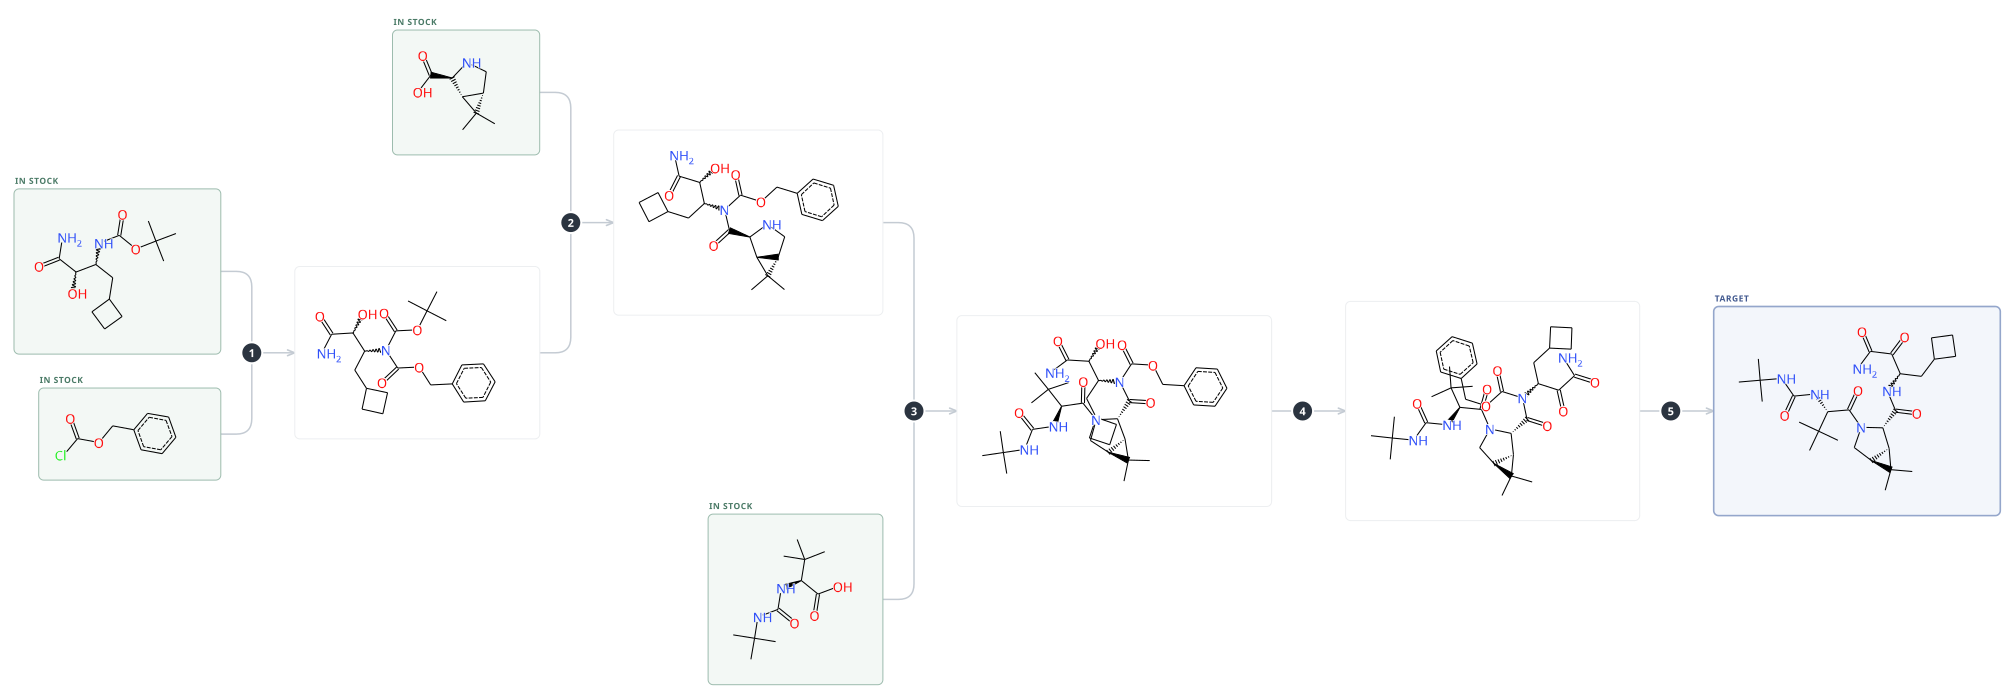

In [13]:
if revision is not None:
    display(selected_route)

### Revised route

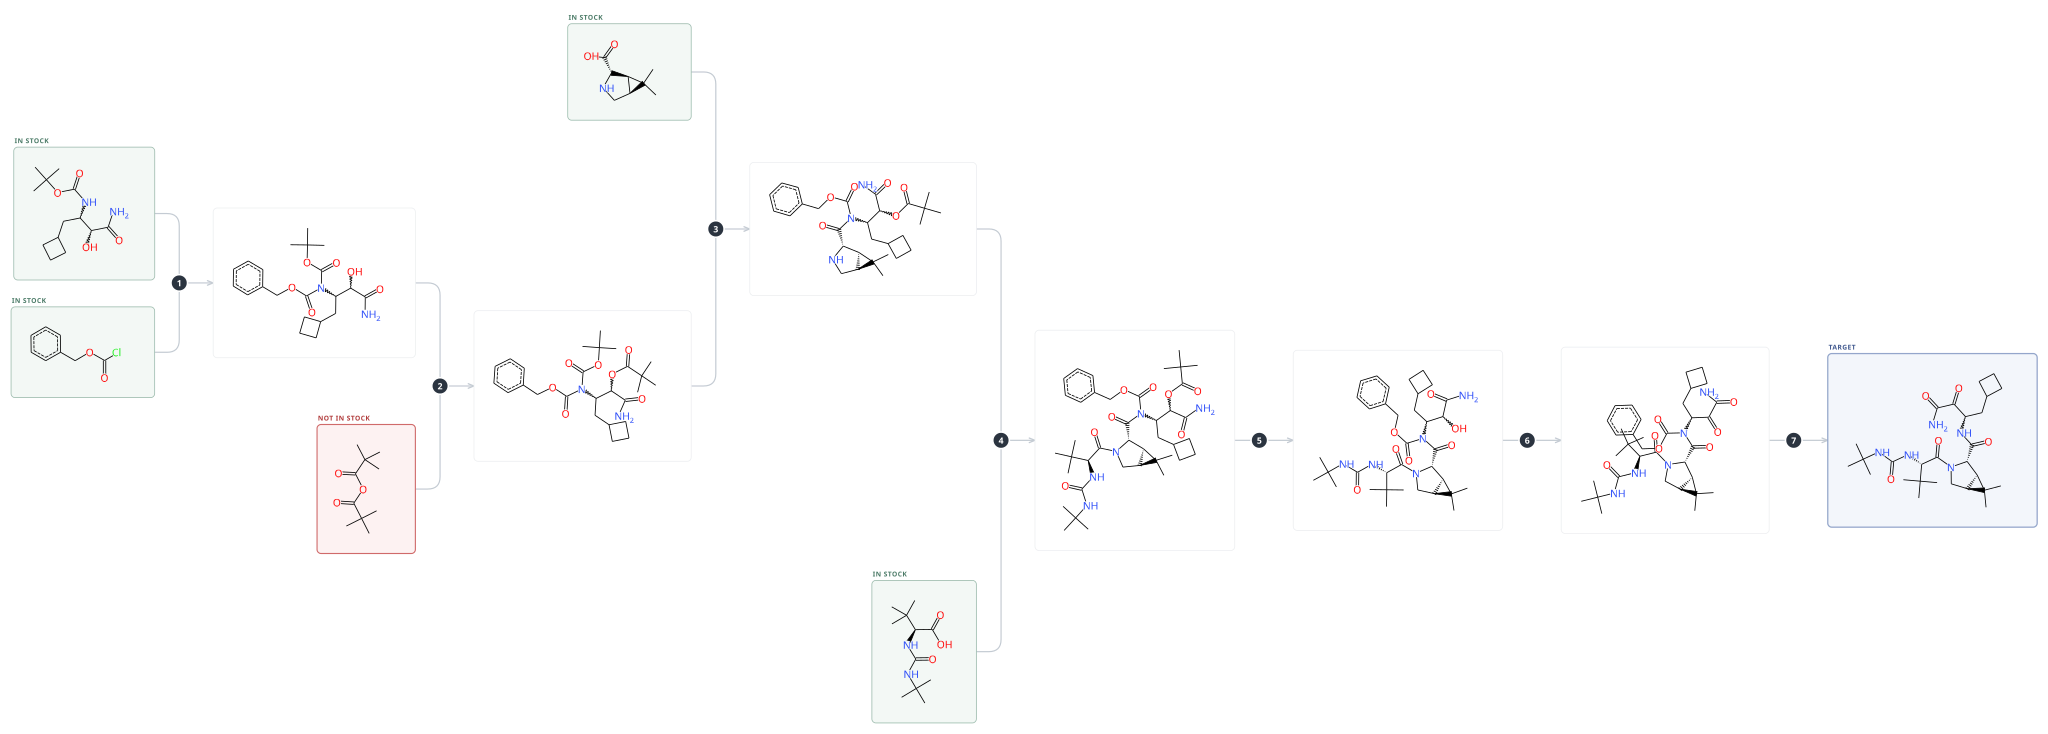

In [14]:
if revision is not None:
    display(revision.route)

### Follow the protecting group

Read the protection step, the transformations carrying the group, and the later
deprotection step in the revised plan.
The notebook’s problematic secondary alcohol (oxygen 33), these seven groups pass the current revision checks:
Piv, TES, MOM, SEM, TBS, TIPS and TMS.
I tested each at that site. All persist through two transformations and improve the score from 0.70 to 0.929. Piv is selected because it comes first in the deterministic ranking when scores tie.

In [15]:
if revision is not None:
    actions = [
        {
            "Protecting group": a.protection_class.split(" ", 1)[-1].removesuffix(
                " protection"
            ),
            "Protection step": a.new_step_ids[0] + 1,
            "Protected transformations": ", ".join(
                str(i + 1) for i in a.protected_step_ids
            ),
            "Deprotection step": a.new_step_ids[2] + 1,
        }
        for a in revision.actions
    ]
    display(pd.DataFrame(actions).style.hide(axis="index"))
    display(
        Markdown(
            "**The SB-CGR did not change:** the revised plan preserves the original strategic-bond chemistry."
        )
    )

Protecting group,Protection step,Protected transformations,Deprotection step
O-Piv,2,"3, 4",5


**The SB-CGR did not change:** the revised plan preserves the original strategic-bond chemistry.